# Single-path trajectory analogs for ReLU nets

The ReLU counterpart of the single-path DLGN trajectory study
(*Layers as Lenses*, Sec. 3.3), built so the **hierarchy-seeking lens theorem** (Thm. 1)
and the **self-opposing lens theorem** (Thm. 2) have a direct empirical analog.

Two models, same data, same hand-picked first-layer initialisation, no biases anywhere,
and in both cases **only $W_1$ is trained**, under population gradient flow.

### Experiment A — one hidden layer (no lens)

$$\hat y(x) = \sum_{k=1}^{D} a_k\,\phi(w_k^\top x),\qquad a \in \{\pm1\}^{D}\ \text{frozen}.$$

$$-\nabla_{w_k}\mathcal{L}
= \mathbb{E}\Big[\underbrace{\sigma(-y\hat y)}_{\text{Residue}}\;
\underbrace{a_k}_{\text{Lens}}\;
\underbrace{\mathbb{1}[w_k^\top x>0]}_{\text{Blinder}}\;y\,x\Big].$$

The lens $\Lambda_k \equiv a_k$ is a **constant**: it does not depend on $x$, and it does
not depend on the other neurons. The dual role collapses — $w_k$ is a separator, but it
is nobody's lens. The only coupling left between neurons is the shared residue.

### Experiment B — two hidden layers, frozen sign patterns (lens restored)

$$\hat y(x) = \sum_{s\in\{\pm1\}^D} a_s\,\phi\Big(\sum_{k=1}^{D} s_k\,\phi(w_k^\top x)\Big),
\qquad
\Lambda_k(x)=\sum_{s} a_s\,s_k\,\mathbb{1}\Big[\textstyle\sum_j s_j \phi(w_j^\top x)>0\Big].$$

Layer 2 has one frozen neuron per sign pattern $s \in \{+1,-1\}^D$; the output is a frozen
$\pm1$ per unit. Now $\Lambda_k$ is built from *all* first-layer neurons through the
layer-2 gates, so each $w_k$ is again both a separator and a component of everyone else's
lens. The frozen second layer is how a ReLU net forms conjunctions of its gates — the
replacement for the DLGN's product $\prod_{\kappa\ne k}\phi(w_\kappa^\top x)$.

### Why A is the control that makes B mean something

For $\ell \neq k$ the cross-neuron second-order response in **A** can be written down in
closed form (only the residue depends on $w_\ell$):

$$\lim_{\epsilon\to0}\frac1\epsilon\Big[-\nabla_{w_k}\mathcal{L}(W+\epsilon P_\ell h)
+\nabla_{w_k}\mathcal{L}(W)\Big]\cdot z
= -\,a_k a_\ell\,
\mathbb{E}\big[\sigma'(-y\hat y)\,g_k g_\ell\,(h^\top x)(z^\top x)\big],$$

with $g_k = \mathbb{1}[w_k^\top x>0]$. At an initialisation orthogonal to the ODT
directions, $g_k g_\ell$ is (nearly) independent of the $u_i,u_j$ coordinates of $x$, and
$\mathbb{E}[(u_j^\top x)(u_i^\top x)] = 0$ for $i \neq j$ — so this response survives
*only* through the label-dependence of $\sigma'$. It should be small, and its sign should
be close to chance.

In **B** the lens supplies an additional, structurally different channel. So the
comparison to look at is not just sign agreement but **magnitude**: how much bigger is the
hierarchy-seeking response once the lens exists?

### One ReLU-specific caveat on the initialisation

The paper starts from $W=0$, fine for DLGN ($\phi$ is a soft gate, $\phi(0)=\tfrac12$).
For ReLU, $W_1=0$ gives $h_1 \equiv 0$ and the gradient vanishes identically — an exactly
degenerate stationary point, in both A and B. The init below is therefore *paper
perturbation + a small component orthogonal to every ODT direction*, which is also the
regime the theorems assume ($w_\lambda$ nearly orthogonal to all $u_i$, $d \gg D$).

In [1]:
from itertools import product
from pathlib import Path
import pickle
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

%load_ext autoreload
%autoreload 2

from layer_lenses.odt import generate_cob_odt_data, odt_leaf_ids_for_x
from layer_lenses.relu_analysis import (
    activation_tensor_by_layer_neuron_data,
    collect_start_end_metrics,
    first_layer_neuron_weighted_lens,
    log_loss_gradients,
)
from layer_lenses.relu_mlp import ReLUMLP
from layer_lenses.relu_training import (
    ReLUTrainConfig,
    checkpoint_model_from_state,
    train_relu_mlp,
)
from layer_lenses.utilities import plot_complete_binary_tree_values

print("cuda available:", torch.cuda.is_available())

cuda available: True


## 1. Configuration

Gradient-flow settings: full batch (population gradient), plain SGD with no momentum and
no weight decay, and `lr_scheduler_eta_min_ratio=1.0` so the step size stays **constant**
(the cosine schedule would otherwise decay it). `LR` is the flow step size.

In [2]:
# --- problem ---------------------------------------------------------------
DIM = 100
DEPTH = 4                      # D: ODT depth = number of first-layer neurons
N_TRAIN = 1_000_000              # population sample for the gradient
DATA_SEED = 178                # paper's trajectory figure used seed tag 0178

WIDTH_1 = DEPTH                # D trainable first-layer neurons (both experiments)
WIDTH_2 = 2**DEPTH             # experiment B only: one frozen neuron per sign pattern

# --- frozen output vectors -------------------------------------------------
OUTPUT_SIGN_SEED = 178

# --- initialisation --------------------------------------------------------
EPS = 0.01                      # paper's epsilon in the Sec. 3.3 perturbation
INIT_RANDOM_SCALE = 0.0       # size of the off-ODT ("spurious") init component
INIT_RANDOM_SEED = 178

# --- gradient flow ---------------------------------------------------------
TOTAL_EPOCHS = 2_000
LR = 0.25
TRAIN_SEED = 178

# --- analysis --------------------------------------------------------------
COS_THRESHOLD = 0.85
TRAJ_EPOCH_LIMIT = None           # e.g. 400 to match the paper's 400-epoch figure
GRAD_TRAJ_MAX_CHECKPOINTS = 150   # checkpoints used for the gradient-trajectory figures
PROBE_N = 100_000                 # per split-half probe sample (needs 2 * PROBE_N <= N_TRAIN)
PROBE_EPS = 1e-2                  # finite-difference step; smaller values are noise-dominated,
                                  # see the split-half stability check in Sec. 4.5

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

SNAPSHOT_EPOCHS = tuple(sorted(set(range(0, min(500, TOTAL_EPOCHS) + 1))
                               | set(range(0, TOTAL_EPOCHS + 1, 10))))

NUM_INTERNAL_NODES = 2**DEPTH - 1
NUM_LEAVES = 2**DEPTH
NODE_LEVEL = np.floor(np.log2(np.arange(NUM_INTERNAL_NODES) + 1)).astype(int)
DEEP_NODES = [i for i in range(NUM_INTERNAL_NODES) if NODE_LEVEL[i] == DEPTH - 1]

print(f"experiment A: {DIM} -> {WIDTH_1} (trainable) -> 1 (frozen +-1)")
print(f"experiment B: {DIM} -> {WIDTH_1} (trainable) -> {WIDTH_2} (frozen signs) -> 1 (frozen +-1)")
print(f"ODT: depth {DEPTH}, internal nodes 0..{NUM_INTERNAL_NODES - 1}, "
      f"deepest-level nodes {DEEP_NODES}")
print(f"{len(SNAPSHOT_EPOCHS)} snapshots, device={DEVICE}")

experiment A: 100 -> 4 (trainable) -> 1 (frozen +-1)
experiment B: 100 -> 4 (trainable) -> 16 (frozen signs) -> 1 (frozen +-1)
ODT: depth 4, internal nodes 0..14, deepest-level nodes [7, 8, 9, 10, 11, 12, 13, 14]
651 snapshots, device=cuda


## 2. Data and ODT directions

The ODT normals $u_0,\dots,u_{14}$ are orthonormal, so $w\cdot u_i$ are literally the
coordinates of $w$ in the ODT basis — the quantity plotted in the paper's trajectory
figure.

In [3]:
x_all, y_all, tree, meta = generate_cob_odt_data(
    num_data=2 * N_TRAIN, dim=DIM, depth=DEPTH, seed=DATA_SEED
)
x_train, y_train = x_all[:N_TRAIN], y_all[:N_TRAIN]
x_eval, y_eval = x_all[N_TRAIN:], y_all[N_TRAIN:]

U = tree.w_list                                  # (num_internal_nodes, d)
assert np.allclose(U @ U.T, np.eye(U.shape[0]), atol=1e-8), "ODT normals are not orthonormal"

leaf_ids = odt_leaf_ids_for_x(x_train, tree)
leaf_offsets = leaf_ids - NUM_INTERNAL_NODES

print("x_train:", x_train.shape, " positive fraction:", float((y_train == 1).mean()))
print("ODT normals:", U.shape, "(orthonormal)")
meta

x_train: (1000000, 100)  positive fraction: 0.499702
ODT normals: (15, 100) (orthonormal)


{'num_requested': 2000000,
 'num_kept': 2000000,
 'num_pruned': 0,
 'dim': 100,
 'depth': 4,
 'num_internal_nodes': 15,
 'num_leaf_nodes': 16,
 'threshold': 0.0,
 'seed': 178}

## 3. Shared machinery

Everything both experiments need: init construction, the train-first-layer-only wrapper,
ODT-basis trajectories, and the finite-difference second-order probe. Nothing here is
specific to one architecture — the probe takes whatever model it is handed.

In [ ]:
def build_first_layer_weights(
    coeffs: np.ndarray,
    tree,
    *,
    random_scale: float = INIT_RANDOM_SCALE,
    seed: int = INIT_RANDOM_SEED,
) -> np.ndarray:
    """Build W_1 from ODT-basis coefficients plus an off-ODT random component.

    The random part is projected out of the ODT span, so ``w_k . u_i`` equals
    ``coeffs[k, i]`` exactly regardless of ``random_scale``.
    """
    odt_normals = tree.w_list
    weights = np.asarray(coeffs, dtype=np.float64) @ odt_normals
    if random_scale > 0:
        rng = np.random.default_rng(seed)
        spurious = rng.standard_normal(weights.shape)
        spurious -= (spurious @ odt_normals.T) @ odt_normals
        spurious /= np.linalg.norm(spurious, axis=1, keepdims=True)
        weights = weights + random_scale * spurious
    return weights


def first_layer_only_mask(hidden_dims: list[int]) -> dict[str, np.ndarray]:
    """Update mask that trains W_1 and freezes every downstream layer (bias-free models)."""
    mask = {"hidden_layers.0.weight": np.ones((hidden_dims[0], DIM), dtype=np.float32)}
    prev = hidden_dims[0]
    for layer_idx, width in enumerate(hidden_dims[1:], start=1):
        mask[f"hidden_layers.{layer_idx}.weight"] = np.zeros((width, prev), dtype=np.float32)
        prev = width
    mask["output_layer.weight"] = np.zeros((1, prev), dtype=np.float32)
    return mask


def train_first_layer(
    model: ReLUMLP,
    *,
    total_epochs: int = TOTAL_EPOCHS,
    lr: float = LR,
    snapshot_epochs=None,
    show_progress: bool = True,
) -> dict[str, Any]:
    """Population gradient flow on W_1 only, constant step size."""
    if snapshot_epochs is None:
        snapshot_epochs = tuple(e for e in SNAPSHOT_EPOCHS if e <= total_epochs)
    return train_relu_mlp(
        model=model,
        x_train=x_train,
        y_train=y_train,
        config=ReLUTrainConfig(
            epochs=total_epochs,
            lr=lr,
            batch_size=N_TRAIN,               # full batch = population gradient
            seed=TRAIN_SEED,
            device=DEVICE,
            snapshot_epochs=tuple(snapshot_epochs),
            weight_decay=0.0,
            lr_scheduler_eta_min_ratio=1.0,   # constant step size (gradient flow)
            show_progress=show_progress,
            optimizer="sgd",
            momentum=0.0,
            parameter_update_mask=first_layer_only_mask(list(model.hidden_dims)),
        ),
    )

def train_all_layers(
    model: ReLUMLP,
    *,
    total_epochs: int = TOTAL_EPOCHS,
    lr: float = LR,
    snapshot_epochs=None,
    show_progress: bool = True,
) -> dict[str, Any]:
    """Population gradient flow on W_1 only, constant step size."""
    if snapshot_epochs is None:
        snapshot_epochs = tuple(e for e in SNAPSHOT_EPOCHS if e <= total_epochs)
    return train_relu_mlp(
        model=model,
        x_train=x_train,
        y_train=y_train,
        config=ReLUTrainConfig(
            epochs=total_epochs,
            lr=lr,
            batch_size=N_TRAIN,               # full batch = population gradient
            seed=TRAIN_SEED,
            device=DEVICE,
            snapshot_epochs=tuple(snapshot_epochs),
            weight_decay=0.0,
            lr_scheduler_eta_min_ratio=1.0,   # constant step size (gradient flow)
            show_progress=show_progress,
            optimizer="sgd",
            momentum=0.0,
            parameter_update_mask=None,
        ),
    )

def as_run(out: dict[str, Any]) -> dict[str, Any]:
    """Wrap a training output in the seed_result shape used by the analysis helpers."""
    return {
        "master_seed": DATA_SEED,
        "seeds": {"data_seed": DATA_SEED, "train_seed": TRAIN_SEED},
        "tree": tree,
        "meta": meta,
        "data": {"x_train": x_train, "y_train": y_train, "x_eval": x_eval, "y_eval": y_eval},
        "out": out,
    }

In [5]:
def odt_coordinate_trajectories(ckpts, param_key: str = "hidden_layers.0.weight"):
    """Return (epochs, coords[E, K, N_nodes], off_odt_norm[E, K], norms[E, K])."""
    epochs = np.array(sorted(ckpts), dtype=int)
    coords, residual, norms = [], [], []
    for epoch in epochs:
        weights = ckpts[int(epoch)][param_key].numpy()
        projection = weights @ U.T
        coords.append(projection)
        residual.append(np.linalg.norm(weights - projection @ U, axis=1))
        norms.append(np.linalg.norm(weights, axis=1))
    return epochs, np.stack(coords), np.stack(residual), np.stack(norms)


def plot_odt_trajectories(
    epochs,
    values,
    *,
    residual=None,
    epoch_limit=TRAJ_EPOCH_LIMIT,
    ylabel=r"$w_k \cdot u_i$",
    suptitle="",
):
    """Paper-style panel per first-layer neuron, one line per ODT direction."""
    keep = slice(None) if epoch_limit is None else epochs <= epoch_limit
    ep = epochs[keep]
    num_neurons = values.shape[1]
    colors = plt.get_cmap("tab20", NUM_INTERNAL_NODES)

    fig, axes = plt.subplots(
        1, num_neurons, figsize=(4.6 * num_neurons, 4.4), sharey=True, squeeze=False
    )
    for k in range(num_neurons):
        ax = axes[0, k]
        for node_id in range(NUM_INTERNAL_NODES):
            deep = node_id in DEEP_NODES
            ax.plot(
                ep,
                values[keep, k, node_id],
                color=colors(node_id),
                ls="dashed" if deep else "solid",
                lw=1.3 if deep else 1.8,
                label=f"$u_{{{node_id}}}$",
            )
        if residual is not None:
            ax.plot(ep, residual[keep, k], color="k", ls="dotted", lw=1.6, label="off-ODT norm")
        ax.axhline(0.0, color="k", lw=0.6)
        ax.set_title(rf"$w_{{{k + 1}}}$")
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.2)
    axes[0, 0].set_ylabel(ylabel)
    axes[0, -1].legend(fontsize=7, ncol=2, loc="center left", bbox_to_anchor=(1.02, 0.5))
    if suptitle:
        fig.suptitle(suptitle, y=1.03)
    fig.tight_layout()
    return fig, axes


def gradient_trajectory(out, ckpts, *, max_checkpoints: int = GRAD_TRAJ_MAX_CHECKPOINTS):
    """ODT-basis coordinates of the negative population gradient across checkpoints."""
    available = sorted(ckpts)
    chosen = [
        available[i]
        for i in np.unique(np.linspace(0, len(available) - 1, max_checkpoints).astype(int))
    ]
    coords = []
    for epoch in chosen:
        model_at_epoch = checkpoint_model_from_state(out["model"], ckpts[epoch])
        grads = log_loss_gradients(model=model_at_epoch, x=x_train, y=y_train, device=DEVICE)
        coords.append((-grads["hidden_layers.0.weight"].numpy()) @ U.T)
    return np.array(chosen, dtype=int), np.stack(coords)


def upsilon_summary(weights: np.ndarray) -> pd.DataFrame:
    """Per-neuron argmax ODT direction, the paper's compact solution label."""
    coords = weights @ U.T
    norms = np.linalg.norm(weights, axis=1)
    upsilon = np.abs(coords).argmax(axis=1)
    signed = coords[np.arange(weights.shape[0]), upsilon]
    table = pd.DataFrame(
        {
            "neuron": [f"w{k + 1}" for k in range(weights.shape[0])],
            "upsilon_node": upsilon,
            "odt_level": NODE_LEVEL[upsilon],
            "signed_coord": signed,
            "cos": signed / np.maximum(norms, 1e-12),
            "norm": norms,
            "off_odt_norm": np.linalg.norm(weights - coords @ U, axis=1),
        }
    )
    table["aligned"] = table["cos"].abs() >= COS_THRESHOLD
    print("upsilon tuple:", [int(v) for v in upsilon])
    print("signed solution:",
          [f"{'+' if c > 0 else '-'}u{int(n)}" for c, n in zip(signed, upsilon)])
    return table


def capture_epoch_table(epochs, coords, norms) -> pd.DataFrame:
    """First epoch at which some first-layer neuron reaches |cos| >= COS_THRESHOLD."""
    abs_cos = np.abs(coords) / np.maximum(norms[:, :, None], 1e-12)
    rows = []
    for node_id in range(NUM_INTERNAL_NODES):
        hit = np.nonzero((abs_cos[:, :, node_id] >= COS_THRESHOLD).any(axis=1))[0]
        rows.append(
            {
                "odt_node_id": node_id,
                "odt_level": int(NODE_LEVEL[node_id]),
                "first_epoch": float(epochs[hit[0]]) if hit.size else np.nan,
            }
        )
    return pd.DataFrame(rows)

In [6]:
def lens_matrix(model: ReLUMLP, x: np.ndarray, device: str = DEVICE) -> np.ndarray:
    """Lambda_k(x) for every first-layer neuron: shape (width_0, n).

    Works for both architectures: with one hidden layer this returns
    ``a_k * 1[w_k . x > 0]``; with the frozen sign-pattern layer it returns the
    path-summed downstream coefficient.
    """
    acts = activation_tensor_by_layer_neuron_data(model=model, x_eval=x, device=device)
    state = model.state_dict()
    return np.stack(
        [
            first_layer_neuron_weighted_lens(
                state_dict=state, activation_tensor=acts, first_layer_neuron_id=k
            )
            for k in range(model.hidden_layers[0].out_features)
        ]
    )


def check_lens_reproduces_gradient(model: ReLUMLP, x: np.ndarray, y: np.ndarray) -> float:
    """Rebuild -grad from residue x lens x blinder x y*x and compare against autograd."""
    lens = lens_matrix(model, x)
    with torch.no_grad():
        logits = model(torch.from_numpy(x).float().to(DEVICE)).cpu().numpy()
    residue = 1.0 / (1.0 + np.exp(y * logits))              # sigma(-y * yhat)
    manual = (residue * y * lens) @ x / x.shape[0]
    autograd = -log_loss_gradients(
        model=model, x=x, y=y, device=DEVICE
    )["hidden_layers.0.weight"].numpy()
    difference = float(np.abs(manual - autograd).max())
    print(f"max |manual - autograd| = {difference:.3e} "
          f"(relative {difference / np.abs(autograd).max():.3e})")
    assert np.allclose(manual, autograd, atol=1e-6), \
        "lens decomposition does not reproduce the gradient"
    return difference


def ancestors_with_side(node_id: int) -> list[tuple[int, int]]:
    """[(ancestor_id, +1 if node is in its left subtree else -1), ...], root first.

    Convention from ``odt.py``: a point goes right when ``x . u_i > 0``, so node
    ``2i + 1`` is the left child.
    """
    pairs = []
    node = node_id
    while node > 0:
        parent = (node - 1) // 2
        pairs.append((parent, 1 if node == 2 * parent + 1 else -1))
        node = parent
    return pairs[::-1]


def second_order_probe(
    template_model: ReLUMLP,
    state_dict: dict[str, torch.Tensor],
    *,
    perturb_neuron: int,
    perturb_dir: np.ndarray,
    x: np.ndarray,
    y: np.ndarray,
    eps: float = PROBE_EPS,
    device: str = DEVICE,
) -> np.ndarray:
    """Central-difference d/d(eps) of the negative first-layer gradient: (width_0, d)."""
    weights = state_dict["hidden_layers.0.weight"].numpy().copy()
    grads = []
    for sign in (+1.0, -1.0):
        perturbed = weights.copy()
        perturbed[perturb_neuron] = perturbed[perturb_neuron] + sign * eps * perturb_dir
        probe_state = {key: value.clone() for key, value in state_dict.items()}
        probe_state["hidden_layers.0.weight"] = torch.as_tensor(perturbed, dtype=torch.float32)
        probe_model = checkpoint_model_from_state(template_model, probe_state)
        grads.append(
            -log_loss_gradients(model=probe_model, x=x, y=y, device=device)[
                "hidden_layers.0.weight"
            ].numpy()
        )
    return (grads[0] - grads[1]) / (2.0 * eps)


def hierarchy_seeking_table(
    template_model: ReLUMLP,
    state_dict: dict[str, torch.Tensor],
    *,
    x_a: np.ndarray,
    y_a: np.ndarray,
    x_b: np.ndarray,
    y_b: np.ndarray,
    output_signs=None,
) -> pd.DataFrame:
    """Theorem-1 responses on two disjoint data halves, for every (ell, j, k, ancestor)."""
    state_dict = {key: value.clone() for key, value in state_dict.items()}
    if output_signs is not None:
        width = state_dict["output_layer.weight"].shape[1]
        state_dict["output_layer.weight"] = torch.as_tensor(
            np.asarray(output_signs, dtype=np.float64), dtype=torch.float32
        ).reshape(1, width)

    rows = []
    for ell in range(WIDTH_1):
        for j in DEEP_NODES:
            resp_a = second_order_probe(
                template_model, state_dict,
                perturb_neuron=ell, perturb_dir=U[j], x=x_a, y=y_a,
            )
            resp_b = second_order_probe(
                template_model, state_dict,
                perturb_neuron=ell, perturb_dir=U[j], x=x_b, y=y_b,
            )
            for k in range(WIDTH_1):
                if k == ell:
                    continue
                for ancestor, side in ancestors_with_side(j):
                    z = side * U[ancestor]
                    value_a, value_b = float(resp_a[k] @ z), float(resp_b[k] @ z)
                    rows.append(
                        {
                            "perturbed_neuron": ell,
                            "h_node": j,
                            "observed_neuron": k,
                            "ancestor_node": ancestor,
                            "ancestor_level": int(NODE_LEVEL[ancestor]),
                            "predicted_sign": side,
                            "response": 0.5 * (value_a + value_b),
                            "response_half_a": value_a,
                            "response_half_b": value_b,
                            "sign_stable": (value_a > 0) == (value_b > 0),
                        }
                    )
    table = pd.DataFrame(rows)
    table["matches_theorem"] = table["response"] > 0
    return table


def report_hierarchy_seeking(table: pd.DataFrame, label: str) -> dict[str, float]:
    """Print the agreement and the reliability of the estimate behind it."""
    stability = float(table["sign_stable"].mean())
    correlation = float(
        np.corrcoef(table["response_half_a"], table["response_half_b"])[0, 1]
    )
    agreement = float(table["matches_theorem"].mean())
    print(f"[{label}] split-half sign stability {stability:.3f} (correlation {correlation:.3f})")
    if stability < 0.9:
        print("  NOTE: the halves often disagree on sign. Either the finite difference is "
              "under-resolved (raise PROBE_EPS or PROBE_N), or the true response is near "
              "zero -- the expected outcome for the no-lens model. Compare the median "
              "magnitude across experiments before concluding.")
    print(f"[{label}] Theorem-1 sign agreement {agreement:.3f} "
          f"({int(table['matches_theorem'].sum())}/{len(table)}), "
          f"median |response| {float(table['response'].abs().median()):.3e}")
    return {
        "thm1_agreement": agreement,
        "split_half_stability": stability,
        "median_abs_response": float(table["response"].abs().median()),
        "median_response": float(table["response"].median()),
    }


assert 2 * PROBE_N <= N_TRAIN, "need two disjoint probe halves; lower PROBE_N"
x_probe_a, y_probe_a = x_train[:PROBE_N], y_train[:PROBE_N]
x_probe_b, y_probe_b = x_train[PROBE_N : 2 * PROBE_N], y_train[PROBE_N : 2 * PROBE_N]
print(f"probe halves: {x_probe_a.shape[0]} + {x_probe_b.shape[0]} points, eps={PROBE_EPS}")

probe halves: 100000 + 100000 points, eps=0.01


## 4. Hand-picked first-layer initialisation

**This is the cell to edit.** `INIT_COEFFS[k, i]` is the coefficient of $u_i$ in
$w_k(0)$; everything else is derived, and both experiments start from it. The default
reproduces the paper's Sec. 3.3 perturbation for $D=4$,

$$w_1 = 0,\quad w_2 = -\epsilon v,\quad w_3 = -\epsilon v - \epsilon u_7,\quad
w_4 = -\epsilon v - \epsilon u_8, \qquad v = u_7+u_8+u_9+u_{10},$$

plus the small off-ODT component. From $w_1$'s viewpoint the other neurons have moved
along $-u_7,\dots,-u_{10}$, so Thm. 1 predicts an increased push on $w_1$ toward $-u_0$;
the extra $-\epsilon u_7$, $-\epsilon u_8$ on $w_3,w_4$ should similarly push $w_2$ toward
$-u_1$. The DLGN run converged to $\upsilon = [0, 1, 7, 8]$.

To give one experiment a different init, assign to `coeffs_A` / `coeffs_B` in its build
cell instead of editing this one.

In [7]:
V_NODES = [11, 12, 13, 14]     # paper's v = u_7 + u_8 + u_9 + u_10

# Row k = first-layer neuron k, column i = coefficient on ODT normal u_i.
INIT_COEFFS = np.zeros((WIDTH_1, NUM_INTERNAL_NODES), dtype=np.float64)

for node in V_NODES:        
    INIT_COEFFS[1, node] += EPS
    INIT_COEFFS[2, node] += EPS
    INIT_COEFFS[3, node] += EPS
INIT_COEFFS[2, 13] += EPS   
INIT_COEFFS[3, 14] += EPS    

# ---------------------------------------------------------------------------

W1_INIT = build_first_layer_weights(INIT_COEFFS, tree)

init_view = pd.DataFrame(
    W1_INIT @ U.T,
    index=[f"w{k + 1}" for k in range(WIDTH_1)],
    columns=[f"u{i}" for i in range(NUM_INTERNAL_NODES)],
)
init_view["||w||"] = np.linalg.norm(W1_INIT, axis=1)
init_view["off-ODT norm"] = np.linalg.norm(W1_INIT - (W1_INIT @ U.T) @ U, axis=1)
init_view.round(4)

,u0,u1,u2,u3,u4,u5,u6,u7,u8,u9,u10,u11,u12,u13,u14,||w||,off-ODT norm
w1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00,0.0000,0.0
w2,0.0,-0.0,-0.0,0.0,-0.0,0.0,-0.0,0.0,-0.0,0.0,-0.0,0.01,0.01,0.01,0.01,0.0200,0.0
w3,0.0,-0.0,-0.0,0.0,0.0,0.0,-0.0,0.0,-0.0,0.0,-0.0,0.01,0.01,0.02,0.01,0.0265,0.0
w4,0.0,-0.0,-0.0,0.0,-0.0,0.0,-0.0,0.0,-0.0,0.0,0.0,0.01,0.01,0.01,0.02,0.0265,0.0


## 5. Experiment A — one hidden layer, no lens

$d \to D \to 1$, output weights frozen at $a \in \{\pm1\}^D$. The lens is the constant
$a_k$, so this run shows what the trajectory looks like when a neuron is a separator and
nothing else. Everything downstream in the notebook then asks what the lens adds.

In [115]:
ONE_LAYER_OUTPUT_PRESETS = {
    "random": np.random.default_rng(OUTPUT_SIGN_SEED).choice([-1.0, 1.0], size=WIDTH_1),
    "all_positive": np.ones(WIDTH_1),
    "half_half": np.array([1.0, 1.0, -1.0, -1.0])[:WIDTH_1],
}
ONE_LAYER_OUTPUT_CHOICE = "all_positive"
OUTPUT_SIGNS_A = np.asarray(
    ONE_LAYER_OUTPUT_PRESETS[ONE_LAYER_OUTPUT_CHOICE], dtype=np.float64
).reshape(WIDTH_1)


def build_one_layer_model(w1_init: np.ndarray, output_signs=OUTPUT_SIGNS_A) -> ReLUMLP:
    """d -> D ReLU layer (trainable) -> 1 output with frozen +-1 weights."""
    model = ReLUMLP(input_dim=DIM, hidden_dims=[WIDTH_1], bias=False, activation="relu_one_at_zero")
    with torch.no_grad():
        model.hidden_layers[0].weight.copy_(torch.as_tensor(w1_init, dtype=torch.float32))
        model.output_layer.weight.copy_(
            torch.as_tensor(output_signs, dtype=torch.float32).reshape(1, WIDTH_1)
        )
    return model


coeffs_A = INIT_COEFFS                      # override here for a different init in A
model_A = build_one_layer_model(build_first_layer_weights(coeffs_A, tree))

print("a =", OUTPUT_SIGNS_A)
out_A = train_first_layer(model_A)
ckpts_A = out_A["checkpoint_snapshots"]
epochs_A = sorted(ckpts_A)
FINAL_EPOCH_A = epochs_A[-1]

print("checkpoints:", len(epochs_A), "final epoch:", FINAL_EPOCH_A)
pd.DataFrame(collect_start_end_metrics(as_run(out_A)))

a = [1. 1. 1. 1.]


Training ReLU MLP:   0%|          | 0/2001 [00:00<?, ?it/s]

checkpoints: 651 final epoch: 2000


,timepoint,epoch,train_log_loss,test_error
0,start,0,0.693504,0.499561
1,end,2000,0.671962,0.499561


### Checks: the output weights stayed frozen, and the lens really is constant

The second assertion is the content of this experiment: $\Lambda_k(x)$ takes only the two
values $\{0, a_k\}$ — zero where the blinder closes, $a_k$ everywhere else. Nothing about
the other neurons enters.

In [116]:
first_state_A, last_state_A = ckpts_A[epochs_A[0]], ckpts_A[FINAL_EPOCH_A]
assert torch.equal(first_state_A["output_layer.weight"], last_state_A["output_layer.weight"]), \
    "output weights moved"
assert np.allclose(first_state_A["hidden_layers.0.weight"].numpy() @ U.T, coeffs_A, atol=1e-5), \
    "first-layer init does not match coeffs_A"
print("frozen output unchanged; init matches coeffs_A")

final_model_A = checkpoint_model_from_state(out_A["model"], ckpts_A[FINAL_EPOCH_A])
check_lens_reproduces_gradient(final_model_A, x_train[:20_000], y_train[:20_000])

lens_A = lens_matrix(final_model_A, x_train[:20_000])
for k in range(WIDTH_1):
    values = np.unique(np.round(lens_A[k], 8))
    print(f"  lens values for w{k + 1}: {values}  (a_{k + 1} = {OUTPUT_SIGNS_A[k]:+.0f}, "
          f"blinder open on {float((lens_A[k] != 0).mean()):.3f} of points)")

frozen output unchanged; init matches coeffs_A
max |manual - autograd| = 2.943e-10 (relative 4.695e-07)
  lens values for w1: [0. 1.]  (a_1 = +1, blinder open on 0.497 of points)
  lens values for w2: [0. 1.]  (a_2 = +1, blinder open on 0.496 of points)
  lens values for w3: [0. 1.]  (a_3 = +1, blinder open on 0.495 of points)
  lens values for w4: [0. 1.]  (a_4 = +1, blinder open on 0.495 of points)


### Parameter and gradient trajectories, experiment A

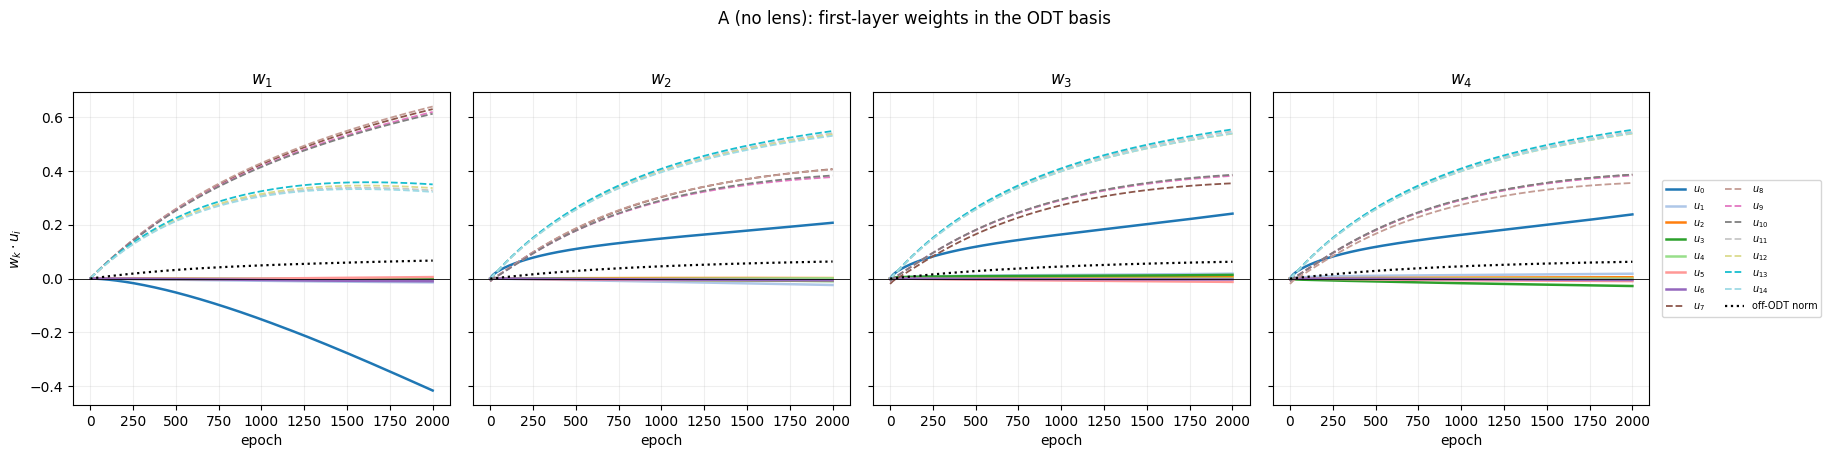

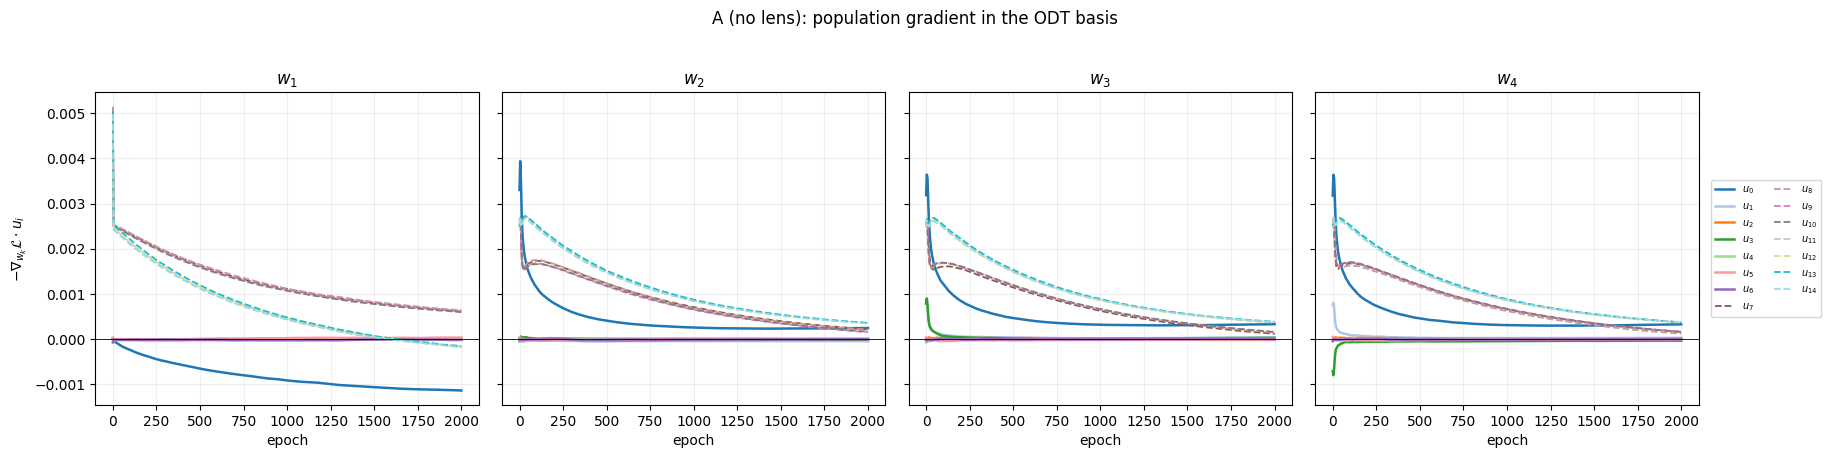

In [117]:
traj_epochs_A, traj_coords_A, traj_residual_A, traj_norms_A = odt_coordinate_trajectories(ckpts_A)

fig_param_A, _ = plot_odt_trajectories(
    traj_epochs_A,
    traj_coords_A,
    residual=traj_residual_A,
    ylabel=r"$w_k \cdot u_i$",
    suptitle="A (no lens): first-layer weights in the ODT basis",
)
plt.show()

grad_epochs_A, grad_coords_A = gradient_trajectory(out_A, ckpts_A)
fig_grad_A, _ = plot_odt_trajectories(
    grad_epochs_A,
    grad_coords_A,
    ylabel=r"$-\nabla_{w_k}\mathcal{L} \cdot u_i$",
    suptitle="A (no lens): population gradient in the ODT basis",
)
plt.show()

In [118]:
summary_A = upsilon_summary(ckpts_A[FINAL_EPOCH_A]["hidden_layers.0.weight"].numpy())
summary_A.round(4)

upsilon tuple: [8, 13, 13, 13]
signed solution: ['+u8', '+u13', '+u13', '+u13']


,neuron,upsilon_node,odt_level,signed_coord,cos,norm,off_odt_norm,aligned
0,w1,8,3,0.6390,0.4322,1.4787,0.0666,False
1,w2,13,3,0.5480,0.4057,1.3509,0.0632,False
2,w3,13,3,0.5543,0.4114,1.3474,0.0624,False
3,w4,13,3,0.5525,0.4099,1.3478,0.0623,False


### Second-order probe without a lens (Theorem 1 analog)

The same finite-difference quantity the paper's theorem is about:

$$\lim_{\epsilon\to0}\frac{1}{\epsilon}\Big[-\nabla_{w_k}\mathcal{L}(W+\epsilon P_\ell h)
+\nabla_{w_k}\mathcal{L}(W)\Big]\cdot z ,\qquad h=u_j,\ z=s\,u_i,$$

with $j$ a deepest-level node, $i$ an ancestor of $j$, and $s=+1$ if $j$ is in $i$'s left
subtree. It is estimated on two disjoint halves of the data so the estimate's own
reliability is visible: with `PROBE_EPS` too small the difference is swamped by sampling
noise, too large and it picks up curvature beyond the derivative. At $d=100$, $n=10^5$
per half, `PROBE_EPS=1e-2` was split-half sign-stable on 95% of entries, `1e-3` on 84%,
`1e-4` on 60%.

Here the closed form from the header applies, so the expectation is a **small** response
with sign near chance — and correspondingly *low* split-half stability, because the
quantity being estimated is itself near zero. That is the expected result here, not a
misconfigured probe. A preliminary run at this config ($d=100$, $10^5$ per half,
`PROBE_EPS=1e-2`, paper init) gave agreement 0.483, split-half stability 0.566, and
median $|$response$|$ of $1.8\times10^{-6}$.

The number to carry forward is that median magnitude, which Experiment B is compared
against.

In [119]:
PROBE_EPOCH_A = epochs_A[0]        # at the hand-picked initialisation

hs_df_A = hierarchy_seeking_table(
    out_A["model"],
    ckpts_A[PROBE_EPOCH_A],
    x_a=x_probe_a, y_a=y_probe_a, x_b=x_probe_b, y_b=y_probe_b,
)
stats_A = report_hierarchy_seeking(hs_df_A, f"A, epoch {PROBE_EPOCH_A}")
hs_df_A.groupby("ancestor_level")[["response", "matches_theorem"]].agg(
    ["mean", "count"]
).round(6)

[A, epoch 0] split-half sign stability 0.625 (correlation 0.231)
  NOTE: the halves often disagree on sign. Either the finite difference is under-resolved (raise PROBE_EPS or PROBE_N), or the true response is near zero -- the expected outcome for the no-lens model. Compare the median magnitude across experiments before concluding.
[A, epoch 0] Theorem-1 sign agreement 0.562 (162/288), median |response| 2.099e-06


response       matches_theorem      
                    mean count            mean count
ancestor_level                                      
0               0.000002    96        0.760417    96
1               0.000001    96        0.583333    96
2               0.000000    96        0.343750    96

## 6. Experiment B — two hidden layers with frozen sign patterns

Now insert the $2^D$ frozen sign-pattern units between the first layer and the output.
Layer-2 row $s$ is a unique $\{+1,-1\}^D$ vector; the label `"+--+"` reads off the sign
each first-layer neuron gets in that unit. The output is a frozen $\pm1$ per unit (set
`OUTPUT_SIGN_CHOICE`, or pass your own vector, to override).

In [9]:
SIGN_PATTERNS = np.array(
    list(product([1.0, -1.0], repeat=WIDTH_1)), dtype=np.float64
)                                                       # (2^D, D)
PATTERN_LABELS = ["".join("+" if v > 0 else "-" for v in row) for row in SIGN_PATTERNS]

OUTPUT_SIGN_PRESETS = {
    # as specified: a random frozen +-1 per unit
    "random": np.random.default_rng(OUTPUT_SIGN_SEED).choice([-1.0, 1.0], size=WIDTH_2),
    # closest analog of the paper's fixed a = 1 > 0
    "all_positive": np.ones(WIDTH_2),
    # +1 when the pattern has at least as many + as - entries
    "majority": np.where(SIGN_PATTERNS.sum(axis=1) >= 0, 1.0, -1.0),
    "parity": SIGN_PATTERNS.prod(axis=1),
}

OUTPUT_SIGN_CHOICE = "all_positive"
OUTPUT_SIGNS_B = np.asarray(
    OUTPUT_SIGN_PRESETS[OUTPUT_SIGN_CHOICE], dtype=np.float64
).reshape(WIDTH_2)

frozen_layers_df = pd.DataFrame(
    {
        "unit": range(WIDTH_2),
        "pattern": PATTERN_LABELS,
        "a_s": OUTPUT_SIGNS_B,
        "sum_s": SIGN_PATTERNS.sum(axis=1),
    }
)
frozen_layers_df

,unit,pattern,a_s,sum_s
0,0,++++,1.0,4.0
1,1,+++-,1.0,2.0
2,2,++-+,1.0,2.0
3,3,++--,1.0,0.0
4,4,+-++,1.0,2.0
5,5,+-+-,1.0,0.0
6,6,+--+,1.0,0.0
7,7,+---,1.0,-2.0
8,8,-+++,1.0,2.0
9,9,-++-,1.0,0.0


In [10]:
def build_frozen_sign_model(
    w1_init: np.ndarray,
    *,
    sign_patterns: np.ndarray = SIGN_PATTERNS,
    output_signs: np.ndarray = OUTPUT_SIGNS_B,
) -> ReLUMLP:
    """ReLU MLP with hand-set first layer and frozen sign-pattern / output layers."""
    model = ReLUMLP(input_dim=DIM, hidden_dims=[WIDTH_1, WIDTH_2], bias=False, activation="relu_one_at_zero")
    with torch.no_grad():
        model.hidden_layers[0].weight.copy_(torch.as_tensor(w1_init, dtype=torch.float32))
        model.hidden_layers[1].weight.copy_(torch.as_tensor(sign_patterns, dtype=torch.float32))
        model.output_layer.weight.copy_(
            torch.as_tensor(output_signs, dtype=torch.float32).reshape(1, WIDTH_2)
        )
    return model


coeffs_B = INIT_COEFFS                      # override here for a different init in B
model_B = build_frozen_sign_model(build_first_layer_weights(coeffs_B, tree))

out_B = train_first_layer(model_B)
ckpts_B = out_B["checkpoint_snapshots"]
epochs_B = sorted(ckpts_B)
FINAL_EPOCH_B = epochs_B[-1]

print("checkpoints:", len(epochs_B), "final epoch:", FINAL_EPOCH_B)
pd.DataFrame(collect_start_end_metrics(as_run(out_B)))

Training ReLU MLP:   0%|          | 0/2001 [00:00<?, ?it/s]

checkpoints: 651 final epoch: 2000


,timepoint,epoch,train_log_loss,test_error
0,start,0,0.691808,0.499561
1,end,2000,0.666710,0.499561


### Checks: frozen layers, and the lens formula

Layers 2 and 3 must be bit-identical to their initial values. Then the same validation as
in A — rebuild $-\nabla_{w_k}\mathcal{L}$ from residue $\times$ lens $\times$ blinder
$\times\,y\,x$ with the lens from `first_layer_neuron_weighted_lens`, and compare against
autograd — which confirms that the object the theory talks about is the object the code
computes.

In [11]:
first_state_B, last_state_B = ckpts_B[epochs_B[0]], ckpts_B[FINAL_EPOCH_B]

assert torch.equal(first_state_B["hidden_layers.1.weight"], last_state_B["hidden_layers.1.weight"]), \
    "layer-2 sign patterns moved"
assert torch.equal(first_state_B["output_layer.weight"], last_state_B["output_layer.weight"]), \
    "output signs moved"
assert np.allclose(first_state_B["hidden_layers.0.weight"].numpy() @ U.T, coeffs_B, atol=1e-5), \
    "first-layer init does not match coeffs_B"
assert not torch.equal(
    first_state_B["hidden_layers.0.weight"], last_state_B["hidden_layers.0.weight"]
), "first layer did not move"
print("frozen layers unchanged; first layer moved; init matches coeffs_B")

final_model_B = checkpoint_model_from_state(out_B["model"], ckpts_B[FINAL_EPOCH_B])
check_lens_reproduces_gradient(final_model_B, x_train[:20_000], y_train[:20_000])

frozen layers unchanged; first layer moved; init matches coeffs_B
max |manual - autograd| = 1.825e-09 (relative 4.869e-07)


1.8246918758943464e-09

### Parameter trajectory (paper Fig. 2, top)

One panel per first-layer neuron; each line is $w_k \cdot u_i$ over epochs. Solid lines
are internal ODT nodes (levels $0..D-2$), dashed lines the deepest-level nodes
($u_7..u_{14}$ for $D=4$), and the black dotted line is the norm of the component
orthogonal to every ODT direction — the "spurious" mass Thm. 2 is about.

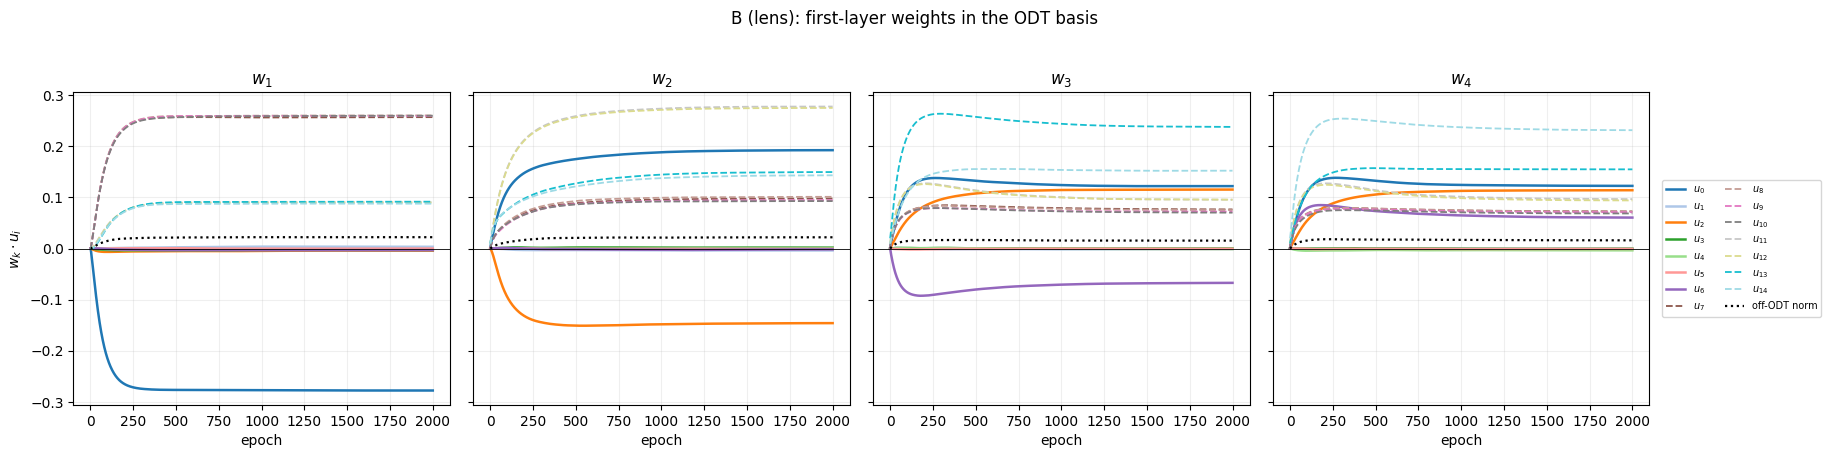

In [12]:
traj_epochs_B, traj_coords_B, traj_residual_B, traj_norms_B = odt_coordinate_trajectories(ckpts_B)

fig_param_B, _ = plot_odt_trajectories(
    traj_epochs_B,
    traj_coords_B,
    residual=traj_residual_B,
    ylabel=r"$w_k \cdot u_i$",
    suptitle="B (lens): first-layer weights in the ODT basis",
)
plt.show()

### Gradient trajectory (paper Fig. 2, bottom)

The same panels for $-\nabla_{w_k}\mathcal{L}\cdot u_i$, i.e. the direction the flow is
currently pushing each neuron. This is where the second-order story is legible in the
DLGN run: the push on $w_1$ toward $-u_0$ builds up *after* the other neurons have moved
along the deepest-level directions, then the push on $w_2$ toward $-u_1$ follows.

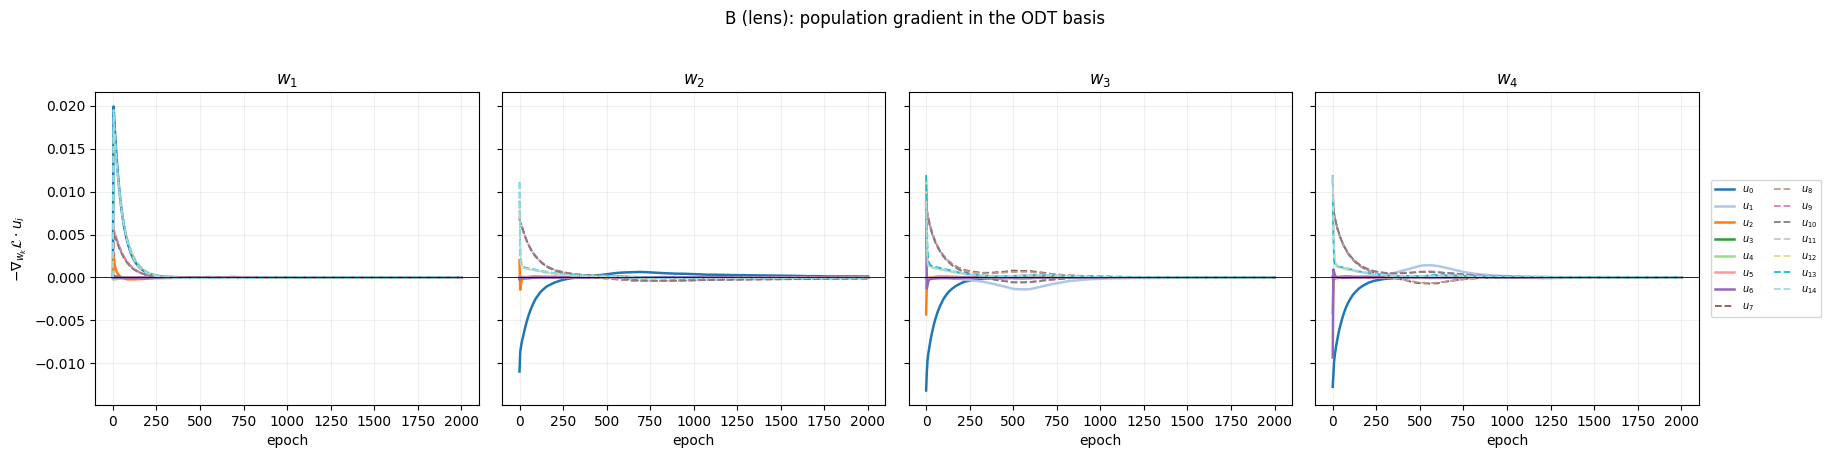

In [140]:
grad_epochs_B, grad_coords_B = gradient_trajectory(out_B, ckpts_B)

fig_grad_B, _ = plot_odt_trajectories(
    grad_epochs_B,
    grad_coords_B,
    ylabel=r"$-\nabla_{w_k}\mathcal{L} \cdot u_i$",
    suptitle="B (lens): population gradient in the ODT basis",
)
plt.show()

### Where each neuron ended up

The $\upsilon$-tuple $\upsilon_k = \arg\max_i |w_k \cdot u_i|$ is the paper's compact
solution label (the DLGN trajectory gave $[0,1,7,8]$).

In [26]:
summary_B = upsilon_summary(ckpts_B[FINAL_EPOCH_B]["hidden_layers.0.weight"].numpy())
summary_B.round(4)

upsilon tuple: [0, 14, 13, 11]
signed solution: ['-u0', '+u14', '+u13', '+u11']


,neuron,upsilon_node,odt_level,signed_coord,cos,norm,off_odt_norm,aligned
0,w1,0,0,-0.2823,-0.4584,0.6158,0.0497,False
1,w2,14,3,0.0817,0.4459,0.1833,0.0348,False
2,w3,13,3,0.2846,0.5483,0.5190,0.0470,False
3,w4,11,3,0.2639,0.5110,0.5164,0.0472,False


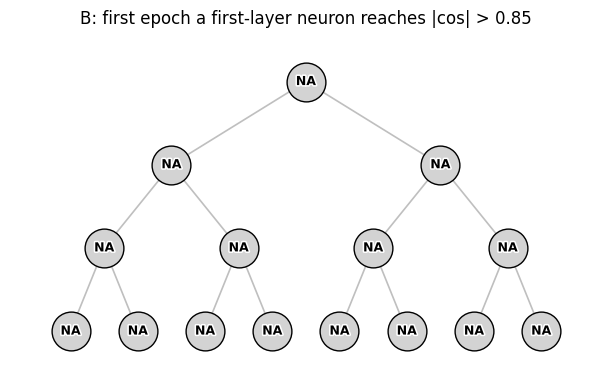

,odt_node_id,odt_level,first_epoch
0,0,0,NaN
1,1,1,NaN
2,2,1,NaN
3,3,2,NaN
4,4,2,NaN
5,5,2,NaN
6,6,2,NaN
7,7,3,NaN
8,8,3,NaN
9,9,3,NaN


In [27]:
capture_df_B = capture_epoch_table(traj_epochs_B, traj_coords_B, traj_norms_B)

fig_tree, _ = plot_complete_binary_tree_values(
    capture_df_B["first_epoch"].to_numpy(dtype=float),
    title=f"B: first epoch a first-layer neuron reaches |cos| > {COS_THRESHOLD}",
    suptitle="",
)
plt.show()
capture_df_B

### The lens, unpacked by sign pattern

$\Lambda_k = \sum_s a_s s_k \mathbb{1}[z_s>0]$ is a sum over the $2^D$ frozen units, so it
can be read off unit by unit: which sign patterns are active, on which ODT leaf regions,
and how much each contributes to the lens of each neuron. This is the ReLU replacement for
"the product of the other gates" — and the thing experiment A does not have.

In [ ]:
final_acts_B = activation_tensor_by_layer_neuron_data(
    model=final_model_B, x_eval=x_train, device=DEVICE
)
unit_active = final_acts_B[1, :WIDTH_2]                  # (2^D, n) layer-2 activity

pattern_df = frozen_layers_df.copy()
pattern_df["active_fraction"] = unit_active.mean(axis=1)
for k in range(WIDTH_1):
    pattern_df[f"lens_share_w{k + 1}"] = (
        OUTPUT_SIGNS_B * SIGN_PATTERNS[:, k] * unit_active.mean(axis=1)
    )
pattern_df.round(4)

In [ ]:
final_lens_B = lens_matrix(final_model_B, x_train)

lens_by_leaf = np.stack(
    [
        np.bincount(leaf_offsets, weights=final_lens_B[k], minlength=NUM_LEAVES)
        / np.maximum(np.bincount(leaf_offsets, minlength=NUM_LEAVES), 1)
        for k in range(WIDTH_1)
    ]
)

fig, ax = plt.subplots(figsize=(10, 3.4))
im = ax.imshow(lens_by_leaf, aspect="auto", cmap="coolwarm",
               vmin=-np.abs(lens_by_leaf).max(), vmax=np.abs(lens_by_leaf).max())
ax.set_yticks(range(WIDTH_1), [f"$w_{{{k + 1}}}$" for k in range(WIDTH_1)])
ax.set_xticks(range(NUM_LEAVES), [str(NUM_INTERNAL_NODES + j) for j in range(NUM_LEAVES)])
ax.set_xlabel("ODT leaf node")
ax.set_title(r"B: mean lens $\Lambda_k(x)$ per ODT leaf region (final epoch)")
fig.colorbar(im, ax=ax)
fig.tight_layout()
plt.show()

pd.DataFrame(
    lens_by_leaf,
    index=[f"w{k + 1}" for k in range(WIDTH_1)],
    columns=[f"leaf{NUM_INTERNAL_NODES + j}" for j in range(NUM_LEAVES)],
).round(4)

### Hierarchy-seeking probe with the lens present (Theorem 1 analog)

Identical measurement to experiment A, on the identical initialisation — the only thing
that changed is that $\Lambda_k$ is now a function of $x$ and of the other neurons.

In [ ]:
PROBE_EPOCH_B = epochs_B[0]        # at the hand-picked initialisation

hs_df_B = hierarchy_seeking_table(
    out_B["model"],
    ckpts_B[PROBE_EPOCH_B],
    x_a=x_probe_a, y_a=y_probe_a, x_b=x_probe_b, y_b=y_probe_b,
)
stats_B = report_hierarchy_seeking(hs_df_B, f"B, epoch {PROBE_EPOCH_B}")
hs_df_B.groupby("ancestor_level")[["response", "matches_theorem"]].agg(
    ["mean", "count"]
).round(6)

In [ ]:
pivot = hs_df_B.pivot_table(
    index=["perturbed_neuron", "h_node"],
    columns=["observed_neuron", "ancestor_node"],
    values="response",
)

fig, ax = plt.subplots(figsize=(13, 6))
limit = np.nanmax(np.abs(pivot.to_numpy()))
im = ax.imshow(pivot.to_numpy(), aspect="auto", cmap="coolwarm", vmin=-limit, vmax=limit)
ax.set_yticks(range(len(pivot.index)),
              [f"$w_{{{ell + 1}}}$ + $u_{{{j}}}$" for ell, j in pivot.index], fontsize=8)
ax.set_xticks(range(len(pivot.columns)),
              [f"$w_{{{k + 1}}}\\cdot s u_{{{i}}}$" for k, i in pivot.columns],
              rotation=90, fontsize=8)
ax.set_title("B: hierarchy-seeking response (red > 0 agrees with Theorem 1)")
fig.colorbar(im, ax=ax)
fig.tight_layout()
plt.show()

### A vs B: what does the lens add?

The comparison this notebook is built around. Same data, same init, same probe — the only
difference is whether a lens exists. Sign agreement alone is not the whole story: the
closed form in the header predicts A's responses should be *small*, so the ratio of
median magnitudes matters as much as the ratio of agreements.

In a preliminary run at this config (probes at the paper init, no training needed) the
split was stark: median $|$response$|$ of $1.8\times10^{-6}$ in A against
$5.0\times10^{-3}$ in B, a factor of roughly $2700$, with split-half stability 0.57 in A
against 0.95 in B. The cross-neuron second-order coupling in this architecture is
essentially *all* lens — the residue channel that A isolates is, as derived, negligible at
an ODT-orthogonal initialisation.

In [ ]:
comparison = pd.DataFrame(
    [
        {"experiment": "A: no lens (d -> D -> 1)", **stats_A},
        {"experiment": f"B: lens (d -> D -> {WIDTH_2} -> 1)", **stats_B},
    ]
)
comparison["magnitude_vs_A"] = (
    comparison["median_abs_response"] / comparison["median_abs_response"].iloc[0]
)
comparison.round(6)

### Swapped roles

Theorem 1 also asserts the inequality with $h$ and $z$ exchanged: perturbing a neuron
along an ancestor direction should increase another neuron's push along the
(sign-corrected) deepest-level direction. That is the other half of the feedback loop.

In [ ]:
swap_rows = []
for ell in range(WIDTH_1):
    for j in DEEP_NODES:
        for ancestor, side in ancestors_with_side(j):
            response = second_order_probe(
                out_B["model"],
                ckpts_B[PROBE_EPOCH_B],
                perturb_neuron=ell,
                perturb_dir=side * U[ancestor],
                x=x_probe_a,
                y=y_probe_a,
            )
            for k in range(WIDTH_1):
                if k == ell:
                    continue
                swap_rows.append(
                    {
                        "perturbed_neuron": ell,
                        "h_node": ancestor,
                        "observed_neuron": k,
                        "z_node": j,
                        "ancestor_level": int(NODE_LEVEL[ancestor]),
                        "response": float(response[k] @ U[j]),
                    }
                )

swap_df = pd.DataFrame(swap_rows)
swap_df["matches_theorem"] = swap_df["response"] > 0
print(f"B swapped-role sign agreement: {swap_df['matches_theorem'].mean():.3f} "
      f"({int(swap_df['matches_theorem'].sum())}/{len(swap_df)})")
swap_df.groupby("ancestor_level")[["response", "matches_theorem"]].agg(
    ["mean", "count"]
).round(6)

### Does the frozen output vector decide whether the effect appears?

$\Lambda_k = \sum_s a_s s_k \mathbb{1}[z_s>0]$ is a **signed** sum, so the frozen $a$
chooses which conjunctions the lens rewards — unlike the DLGN, where the theorem is proved
with a single fixed $a>0$. `all_positive` is that case; `random` is the specification used
above. This cell repeats the full Theorem-1 grid per preset, so it costs one probe grid
per entry.

A preliminary run (d=100, $10^5$ per half, `PROBE_EPS=1e-2`, paper init) gave agreement
`all_positive` 0.93, `majority` 0.94, `parity` 0.76, and for random vectors
0.37 / 0.70 / 0.50 at `OUTPUT_SIGN_SEED` 178 / 0 / 42. With a random $\pm1$ output the
hierarchy-seeking sign structure is therefore seed-dependent and can sit *below* chance,
while the direct analog of the paper's $a>0$ reproduces it strongly. Worth settling before
reading much into a single random draw.

In [ ]:
OUTPUT_SIGN_SWEEP = ["random", "all_positive", "majority", "parity"]

sweep_rows = []
for preset_name in OUTPUT_SIGN_SWEEP:
    table = hierarchy_seeking_table(
        out_B["model"],
        ckpts_B[PROBE_EPOCH_B],
        x_a=x_probe_a, y_a=y_probe_a, x_b=x_probe_b, y_b=y_probe_b,
        output_signs=OUTPUT_SIGN_PRESETS[preset_name],
    )
    sweep_rows.append(
        {
            "output_signs": preset_name,
            "thm1_agreement": table["matches_theorem"].mean(),
            "median_response": table["response"].median(),
            "median_abs_response": table["response"].abs().median(),
            "split_half_stability": table["sign_stable"].mean(),
        }
    )

pd.DataFrame(sweep_rows).round(6)

### Self-opposing probe (Theorem 2 analog)

For $h$ orthogonal to **every** ODT direction, the DLGN theorem says perturbing $w_\ell$
along $h$ increases the push on other neurons along $-h$: neurons amplify each other's
spurious components. Averaged over random spurious directions, a positive response here is
the mechanism behind the off-ODT mass tracked as the black dotted line in the parameter
trajectories.

In [ ]:
SELF_OPPOSING_DIRS = 20

rng = np.random.default_rng(INIT_RANDOM_SEED + 1)
so_rows = []
for trial in range(SELF_OPPOSING_DIRS):
    h = rng.standard_normal(DIM)
    h -= (h @ U.T) @ U                       # orthogonal to every ODT normal
    h /= np.linalg.norm(h)
    ell = trial % WIDTH_1
    for label, template, state in (
        ("A", out_A["model"], ckpts_A[PROBE_EPOCH_A]),
        ("B", out_B["model"], ckpts_B[PROBE_EPOCH_B]),
    ):
        response = second_order_probe(
            template, state, perturb_neuron=ell, perturb_dir=h, x=x_probe_a, y=y_probe_a
        )
        for k in range(WIDTH_1):
            if k == ell:
                continue
            so_rows.append(
                {
                    "experiment": label,
                    "trial": trial,
                    "perturbed_neuron": ell,
                    "observed_neuron": k,
                    "response_along_minus_h": float(response[k] @ (-h)),
                }
            )

so_df = pd.DataFrame(so_rows)
so_df["matches_theorem"] = so_df["response_along_minus_h"] > 0
print(so_df.groupby("experiment")["matches_theorem"].mean().round(3))

fig, ax = plt.subplots(figsize=(7, 4))
for label, group in so_df.groupby("experiment"):
    ax.hist(group["response_along_minus_h"], bins=25, alpha=0.6, label=f"experiment {label}")
ax.axvline(0.0, color="k", lw=1)
ax.set_xlabel(r"response along $-h$  (positive agrees with Theorem 2)")
ax.set_ylabel("count")
ax.set_title("Self-opposing lens probe, spurious directions")
ax.legend()
fig.tight_layout()
plt.show()

so_df.groupby("experiment")["response_along_minus_h"].describe().round(6)

## 7. Sweeping hand-picked initialisations

Edit `INIT_VARIANTS` to compare constructions: each entry is a
`(name, coefficient matrix)` pair, trained in both architectures with identical data and
frozen layers. Use it to check whether different perturbations steer the flow to different
$\upsilon$-tuples — the ReLU version of the paper's claim that any canonical solution is
reachable by a suitable small perturbation — and whether that steering needs the lens.

In [ ]:
def coeffs_paper(eps: float = EPS) -> np.ndarray:
    """Paper Sec. 3.3 perturbation: w1=0, w2=-eps v, w3=-eps v -eps u7, w4=-eps v -eps u8."""
    coeffs = np.zeros((WIDTH_1, NUM_INTERNAL_NODES))
    for node in V_NODES:
        coeffs[1:, node] -= eps
    coeffs[2, 7] -= eps
    coeffs[3, 8] -= eps
    return coeffs


def coeffs_saddle(eps: float = EPS) -> np.ndarray:
    """Symmetric saddle: every neuron at c * sum_j -u_j over deepest-level nodes."""
    coeffs = np.zeros((WIDTH_1, NUM_INTERNAL_NODES))
    coeffs[:, DEEP_NODES] -= eps
    return coeffs


def coeffs_leaf_pair(leaf_a: int = 9, leaf_b: int = 10, eps: float = EPS) -> np.ndarray:
    """Saddle plus tilts toward a different adjacent leaf pair."""
    coeffs = coeffs_saddle(eps)
    coeffs[0] = 0.0
    coeffs[2, leaf_a] -= eps
    coeffs[3, leaf_b] -= eps
    return coeffs


INIT_VARIANTS = {
    "paper (7, 8)": coeffs_paper(),
    "saddle only": coeffs_saddle(),
    "leaf pair (9, 10)": coeffs_leaf_pair(),
}

variant_rows = []
for name, coeffs in INIT_VARIANTS.items():
    w1 = build_first_layer_weights(coeffs, tree)
    for label, builder in (("A", build_one_layer_model), ("B", build_frozen_sign_model)):
        variant_out = train_first_layer(
            builder(w1), snapshot_epochs=(0, TOTAL_EPOCHS), show_progress=False
        )
        weights = variant_out["checkpoint_snapshots"][TOTAL_EPOCHS][
            "hidden_layers.0.weight"
        ].numpy()
        coords = weights @ U.T
        upsilon = np.abs(coords).argmax(axis=1)
        signed = coords[np.arange(WIDTH_1), upsilon]
        variant_rows.append(
            {
                "init": name,
                "experiment": label,
                "upsilon": tuple(int(v) for v in upsilon),
                "signed": tuple(
                    f"{'+' if c > 0 else '-'}u{int(n)}" for c, n in zip(signed, upsilon)
                ),
                "final_log_loss": variant_out["epoch_losses"][-1],
                "max_abs_cos": float(
                    np.max(np.abs(signed) / np.linalg.norm(weights, axis=1))
                ),
            }
        )

pd.DataFrame(variant_rows)

## 8. Notes and open threads

- **Reading the trajectories.** The DLGN narrative to check against: an early phase moving
  to the symmetric saddle, then a push on $w_1$ along $-u_0$ that builds only after the
  other neurons have committed to deepest-level directions, then $w_2$ along $-u_1$, with a
  brief $+u_0$ backlash on the other neurons (Thm. 2) while $w_1$'s push is strongest. If
  that staging shows up in B but not in A, it is the lens doing it.
- **What A can and cannot rule out.** A still couples neurons through the shared residue,
  so it is not a "no interaction" control — it is a "no *multiplicative* interaction"
  control. The closed form in the header says the residue channel should be weak at an
  ODT-orthogonal init, and a preliminary run agrees: the coupling is ~2700x smaller in A
  than in B. So in this architecture the cross-neuron second-order effect is essentially
  all lens. What A does *not* settle is whether the lens channel carries the *sign*
  structure Thm. 1 predicts — that depends on the frozen output vector (next bullet).
- **What differs from DLGN by construction.** The lens in B is a *signed sum* over $2^D$
  frozen units rather than a product, so it can change sign as a function of $x$, and a
  random frozen $a_s$ can make some sign patterns actively unhelpful. In a preliminary run
  this mattered a lot: Theorem-1 agreement ran 0.93-0.94 for $a \ge 0$ / majority signs but
  0.37-0.70 across three random draws. For the closest analog of the paper's theorem use
  `OUTPUT_SIGN_CHOICE = "all_positive"`; for the random-$a$ model as specified, the seed
  dependence is itself the finding to chase.
- **Probe location.** The probes run at the initialisation, where the theorems'
  orthogonality assumptions hold. Re-running with `PROBE_EPOCH_A` / `PROBE_EPOCH_B` set to
  a mid-training checkpoint asks a different and also interesting question: whether the
  sign structure survives once the weights carry real ODT mass.
- **Still to do:** vary $\epsilon$ and `INIT_RANDOM_SCALE` to locate the boundary between
  perturbation-driven and noise-driven outcomes; add $a_s$ hand-designs that let the net
  express a single ODT path; and if the trajectories reproduce the DLGN staging, move
  `odt_coordinate_trajectories`, `second_order_probe`, and `ancestors_with_side` into
  `src/layer_lenses/relu_analysis.py`.